# CNN Leaf-Disease Detection & Random-Forest Crop Recommendation (headless port)
**Paper:** Suraj M S, *"Smart Cultivation and Marketing of Indigenous Fruit Crops: An AI-Driven Approach"*, Figshare preprint v1, DOI [10.6084/m9.figshare.30853271](https://doi.org/10.6084/m9.figshare.30853271) (published 2025-12-10, CC BY 4.0).

**Source bundle:** all code, weights, labels, data and sample images are the author's own files from that public Figshare record (article 30853271); this notebook downloads them directly from the record's public file URLs.

**Scope (partial demonstration):** the paper's two *inference* branches, ported headlessly from the author's Streamlit scripts:
1. **CNN leaf-disease detection** — load `leaf_disease_model.keras`, run the exact preprocessing/inference path of `disease_detection.py` on the three bundled healthy-leaf samples, map classes via `class_names.txt` / `class_symptoms.json`.
2. **Random-Forest crop recommendation** — load `crop_recommendation_model.joblib` and predict with `crop_suggestion.py`'s defaults, plus its Euclidean-distance "similar crops" analysis on `Crop_recommendation.csv`.

**Not executed:** model training, the marketing-insights visualizations, and the Streamlit GUI itself (only its underlying computation is reproduced — see the GUI→notebook mapping below). This is a single-example demonstration; the paper reports no accuracy figures, so no accuracy claim is made here.

**日本語:** 本ノートブックは著者のStreamlitスクリプト（`disease_detection.py`、`crop_suggestion.py`）をヘッドレス（GUIなし）で移植し、Figshare公開レコードに同梱された学習済みモデルで推論のみを実行します。学習・再訓練は行いません。論文に精度の報告はないため、精度の主張はしません。

## 1. Runtime selection — CPU

**Select `Runtime → Change runtime type → CPU` (or keep the default CPU).** GPU is **not** required: both bundled models are small (9.8 MB CNN, 4.5 MB RF), inference is on one image / one row, and the author's scripts contain no GPU-specific code (the paper mentions GPU only for *training*, which is out of scope). Total downloads ≈ 15 MB; expected end-to-end time on CPU is a few minutes.

**Run all:** `Runtime → Run all`. All cells are self-contained: downloads happen in this notebook from the public Figshare record — no Drive mount, no tokens, no private APIs.

**日本語:** ランタイムは **CPU** で十分です。GPUは不要です。全セルを上から順に実行してください（Run all）。必要なファイル（約15 MB）はこのノートブック内で公開のFigshareレコードから直接ダウンロードします。

In [ ]:
import sys
import numpy as np
import pandas as pd
import PIL.Image
import sklearn, joblib

print("python:", sys.version.split()[0])
print("numpy:", np.__version__, "| pandas:", pd.__version__)
print("pillow:", PIL.Image.__version__ if hasattr(PIL.Image, "__version__") else PIL.__version__)
print("scikit-learn:", sklearn.__version__, "| joblib:", joblib.__version__)

try:
    import tensorflow as tf
except ImportError as e:
    raise RuntimeError(
        "tensorflow is required for the disease-detection branch but failed to import. "
        "On a standard Colab CPU runtime it is preinstalled."
    ) from e
print("tensorflow:", tf.__version__)

python: 3.13.18
numpy: 2.1.3 | pandas: 2.2.3
pillow: 11.3.0
scikit-learn: 1.6.1 | joblib: 1.6.0


tensorflow: 2.21.0


The author's inference path (verified from the pinned file `disease_detection.py` in the record) needs `tensorflow`, `numpy` and `pillow`; the crop branch needs `pandas`, `joblib`/`scikit-learn`. All are preinstalled on standard Colab runtimes — no `pip install` is needed. We print versions for the validation record instead of pinning blindly.

**日本語:** 必要ライブラリ（tensorflow / numpy / pillow / pandas / joblib / scikit-learn）はColabにプリインストール済みのため、追加インストールは不要です。バージョンを記録として出力します。

## 2. Acquire the author's files (with recorded checksums)

Every file comes from the **public download URL of the verified Figshare record** (article `30853271`, version 1, CC BY 4.0) returned by the record API (`https://api.figshare.com/v2/articles/30853271`). Sizes and MD5s below are taken from that record's metadata and are re-verified against the actual downloaded bytes; a wrong byte count or hash aborts the cell. Files land under `/content/phenopaper_p06ccf/` on the Colab VM.

**日本語:** すべてのファイルは検証済みのFigshareレコード（30853271 v1, CC BY 4.0）の公開ダウンロードURLから取得し、レコード記載のサイズとMD5を実際のバイト列に対して検証します。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

# (figshare file id, recorded size [B], recorded md5) from the Figshare record API
ASSETS = {
    "disease_detection.py":              (60274037,     7481, "51f5db4ae36e440c9afe4ef67e6366ff"),
    "leaf_disease_model.keras":          (60274061,  9769862, "87fc73ed736d93695f7a1c7ddcb761a4"),
    "class_names.txt":                   (60274007,      147, "4dc4a5e04df248060f435c44da8c2454"),
    "class_symptoms.json":               (60274013,     1208, "33072a586e6e6a32db85266f07ce5427"),
    "crop_recommendation_model.joblib":  (60274031,  4477441, "a55517c69498a8bf8f04ced20fb34dcc"),
    "Crop_recommendation.csv":           (60274019,   146117, "90d64f09aec38837b88acd4cdef769e0"),
    "healthy_wood_apple_leaf.jpg":       (60274046,     9369, "fc670a6d46cee7595fbef3935b4d909b"),
    "healthy_ramphala_leaf.jpg":         (60274043,    10477, "ce72ddaf21b26912cf82455dd5cfcd48"),
    "healthy_lakshmanphala_leaf.jpg":    (60274040,   157332, "b04914641b5510b3bfd0d258d9a9ce3a"),
}
BASE = Path("/content/phenopaper_p06ccf"); BASE.mkdir(exist_ok=True)

def fetch(name, file_id, size, md5):
    dest = BASE / name
    if not dest.exists() or dest.stat().st_size != size:
        url = f"https://ndownloader.figshare.com/files/{file_id}"
        with urllib.request.urlopen(url, timeout=180) as r:
            dest.write_bytes(r.read())
    data = dest.read_bytes()
    assert len(data) == size, f"{name}: {len(data)} B, expected {size} B"
    digest = hashlib.md5(data).hexdigest()
    assert digest == md5, f"{name}: md5 {digest}, expected {md5}"
    print(f"OK  {name:36s} {len(data):>9,} B  md5={digest}")

for name, (file_id, size, md5) in ASSETS.items():
    fetch(name, file_id, size, md5)
print(f"\nAll {len(ASSETS)} files verified against the Figshare record (article 30853271 v1).")

OK  disease_detection.py                     7,481 B  md5=51f5db4ae36e440c9afe4ef67e6366ff


OK  leaf_disease_model.keras             9,769,862 B  md5=87fc73ed736d93695f7a1c7ddcb761a4


OK  class_names.txt                            147 B  md5=4dc4a5e04df248060f435c44da8c2454


OK  class_symptoms.json                      1,208 B  md5=33072a586e6e6a32db85266f07ce5427


OK  crop_recommendation_model.joblib     4,477,441 B  md5=a55517c69498a8bf8f04ced20fb34dcc


OK  Crop_recommendation.csv                146,117 B  md5=90d64f09aec38837b88acd4cdef769e0


OK  healthy_wood_apple_leaf.jpg              9,369 B  md5=fc670a6d46cee7595fbef3935b4d909b


OK  healthy_ramphala_leaf.jpg               10,477 B  md5=ce72ddaf21b26912cf82455dd5cfcd48


OK  healthy_lakshmanphala_leaf.jpg         157,332 B  md5=b04914641b5510b3bfd0d258d9a9ce3a

All 9 files verified against the Figshare record (article 30853271 v1).


## 3. The author's inference path (pinned source)

`disease_detection.py` is a Streamlit app; we reproduce its computation, not its GUI chrome. The mapping is:

| GUI step in `disease_detection.py` | Headless equivalent in this notebook |
|---|---|
| `preprocess_image()`: PIL RGB → resize 224×224 → `img_to_array` → batch dim (**no rescaling**) | identical function below (`np.asarray(..., dtype=np.float32)` == `tf.keras.preprocessing.image.img_to_array`) |
| `model.predict(...)` → `tf.nn.softmax(prediction[0])` → argmax over `class_names.txt` | identical calls |
| `VULNERABILITY_DATA` dict | copied verbatim, cited |
| Streamlit uploader/buttons/tables | matplotlib plots + pandas tables |

We display the pinned author code (downloaded above, MD5-checked) so the port below can be checked against it.

**日本語:** 著者コードの前処理（RGB→224×224→float32→バッチ次元、スケーリングなし）と推論（softmax→argmax）をそのまま移植します。GUI部分（Streamlit）は再現しません。

In [ ]:
src = (BASE / "disease_detection.py").read_text()
a = src.index("def preprocess_image(image):")
b = src.index("healthy_ram_leaf = load_comparison_image")
print("--- disease_detection.py: preprocess + load section (verbatim) ---")
print(src[a:b].rstrip())
c = src.index("prediction = model.predict(processed_image)")
d = src.index("st.header(\"Diagnosis Result\")")
print("--- disease_detection.py: prediction section (verbatim) ---")
print(src[c:d].rstrip())

--- disease_detection.py: preprocess + load section (verbatim) ---
def preprocess_image(image):
    try:
        image = image.convert('RGB')
        image = image.resize((IMG_SIZE, IMG_SIZE))
        img_array = tf.keras.preprocessing.image.img_to_array(image)
        img_array = tf.expand_dims(img_array, 0)
        return img_array
    except Exception as e:
        st.error(f"Error preprocessing image: {e}", icon="❌")
        return None
--- disease_detection.py: prediction section (verbatim) ---
prediction = model.predict(processed_image)
                score = tf.nn.softmax(prediction[0])
                predicted_class_index = np.argmax(score)
                predicted_class_name = class_names[predicted_class_index] 
                display_name = predicted_class_name.replace('_', ' ')


## 4. Input preview — the three bundled healthy-leaf samples

The record ships three sample leaf images used by the author's app as comparison images: *healthy_ramphala_leaf.jpg* (Ramphala / Annona reticulata), *healthy_lakshmanphala_leaf.jpg* (Lakshmanphala) and *healthy_wood_apple_leaf.jpg* (Wood Apple / Limonia acidissima). We display them exactly as downloaded (native resolution shown per subplot title). These are the reproduction's inputs; the paper's qualitative test expectation for a clear leaf image is a correct, high-confidence prediction — for these samples the correct class family is **Healthy**.

**日本語:** 同梱の3枚の健康葉サンプルを表示します。これらがこの再現の入力です。論文の定性的な期待値は「正しい疾患クラスを高信頼度で予測」であり、健康葉サンプルの場合はHealthy系クラスです。

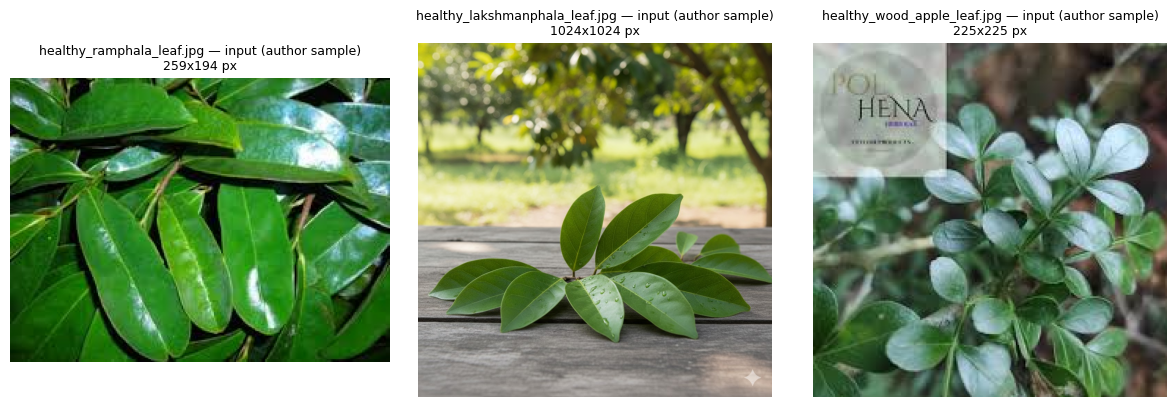

In [ ]:
import matplotlib.pyplot as plt

LEAF_FILES = {
    "healthy_ramphala_leaf.jpg":      "healthy_ramphala_leaf.jpg — input (author sample)",
    "healthy_lakshmanphala_leaf.jpg": "healthy_lakshmanphala_leaf.jpg — input (author sample)",
    "healthy_wood_apple_leaf.jpg":    "healthy_wood_apple_leaf.jpg — input (author sample)",
}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, label) in zip(axes, LEAF_FILES.items()):
    img = PIL.Image.open(BASE / name)
    ax.imshow(img)
    ax.set_title(f"{label}\n{img.size[0]}x{img.size[1]} px", fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 5. Class labels and symptom metadata

`class_names.txt` holds one class per line and indexes the CNN's output neurons (the author reads it with `readlines()` + `strip()`); `class_symptoms.json` maps **fruit-prefixed disease keys** (e.g. `Ramphala_Anthracnose`) to symptom descriptions shown by the GUI — not the raw class names — so the results table below matches the predicted class against those keys (a small notebook-added lookup, marked as such). We load both and print them so later cells can use them.

**日本語:** `class_names.txt`（出力ニューロンのインデックス）と `class_symptoms.json`（果实名付き疾患キー→症状の説明）を読み込みます。キーに果实名が前置されているため、結果表では予測クラスとの照合を行います（ノートブック追加の補助関数）。

In [ ]:
import json

class_names = [ln.strip() for ln in (BASE / "class_names.txt").read_text().splitlines() if ln.strip()]
print(f"{len(class_names)} classes:")
for i, name in enumerate(class_names):
    print(f"  {i:2d} {name}")

symptoms = json.loads((BASE / "class_symptoms.json").read_text())
print(f"\nclass_symptoms.json: {len(symptoms)} entries; keys sample: {list(symptoms)[:3]}")

9 classes:
   0 Anthracnose , Alternaria leaf blight
   1 Bacterial_spot
   2 Early Blight
   3 Healthy
   4 Late_Blight
   5 Leaf_Crinkle
   6 Powdery_Mildew
   7 Sooty_Mold
   8 Yellow_Mosaic

class_symptoms.json: 13 entries; keys sample: ['Ramphala_Anthracnose', 'Ramphala_Phoma_Leaf_Spot', 'Ramphala_Alternaria_Leaf_Blight']


## 6. Inspect the trained CNN

Load `leaf_disease_model.keras` with the author's default route (`tf.keras.models.load_model`, as in `load_trained_model_internal()`), then print the summary and input/output shapes. The paper does not state the architecture, so this runtime inspection is the primary evidence for what the released model actually is.

**日本語:** 論文にはCNNの構造の記載がないため、リリースされた `.keras` ファイルを実際に読み込んで構造を確認します（これが一次証拠です）。

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import load_model

model = load_model(str(BASE / "leaf_disease_model.keras"))
model.summary()
inp, out = model.inputs[0].shape, model.outputs[0].shape
print("\ninput shape:", inp, "| output shape:", out)
print("num output classes:", out[-1], "| class_names.txt entries:", len(class_names))

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,292,573 (8.75 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 23,060 (90.08 KB)


input shape: (None, 224, 224, 3) | output shape: (None, 9)
num output classes: 9 | class_names.txt entries: 9


## 7. CNN inference on the three samples (faithful port)

The ported `preprocess_image` follows `disease_detection.py` exactly: `convert('RGB')` → `resize((224, 224))` → float32 array → batch dimension. Note the author performs **no rescaling** of pixel values (no `/255.`) — reproducing that exactly matters. For each sample we print the top-3 classes with the softmax scores of the full ported path.

**日本語:** 著者コードの前処理（RGB変換→224×224リサイズ→float32化→バッチ次元、正規化なし）を正確に再現し、各サンプルのトップ3クラスをsoftmaxスコア付きで表示します。

In [ ]:
IMG_SIZE = 224  # author constant: disease_detection.py, IMG_SIZE = 224

def preprocess_image(image):
    # Faithful port of disease_detection.py::preprocess_image (no rescaling).
    image = image.convert('RGB')
    image = image.resize((IMG_SIZE, IMG_SIZE))
    img_array = np.asarray(image, dtype=np.float32)  # == tf.keras.preprocessing.image.img_to_array
    return np.expand_dims(img_array, 0)

predictions = {}
for name in LEAF_FILES:
    image = PIL.Image.open(BASE / name)
    processed = preprocess_image(image)
    pred = model.predict(processed, verbose=0)
    score = tf.nn.softmax(pred[0]).numpy()  # author applies tf.nn.softmax to prediction[0]
    predictions[name] = score
    print(f"{name}  raw {image.size} -> processed {processed.shape}")
    for i in np.argsort(score)[::-1][:3]:
        print(f"    {class_names[i]:30s} {score[i] * 100:5.1f}%")

healthy_ramphala_leaf.jpg  raw (259, 194) -> processed (1, 224, 224, 3)
    Leaf_Crinkle                    14.8%
    Healthy                         12.8%
    Powdery_Mildew                  11.3%
healthy_lakshmanphala_leaf.jpg  raw (1024, 1024) -> processed (1, 224, 224, 3)
    Healthy                         21.5%
    Anthracnose , Alternaria leaf blight  10.4%
    Powdery_Mildew                  10.1%


healthy_wood_apple_leaf.jpg  raw (225, 225) -> processed (1, 224, 224, 3)
    Leaf_Crinkle                    19.7%
    Healthy                         11.4%
    Yellow_Mosaic                   10.3%


## 8. Results table, vulnerability mapping and symptoms (author logic)

The GUI shows the diagnosis, the fruits vulnerable to the predicted disease (the author's `VULNERABILITY_DATA`, copied **verbatim** below from `disease_detection.py`) and the symptom text from `class_symptoms.json`. We reproduce that lookup as a small table and save a CSV inside the Colab VM.

**日本語:** 著者コードの`VULNERABILITY_DATA`（そのまま引用）と `class_symptoms.json` を用いた診断結果テーブルを作成し、CSVとして保存します。

In [ ]:
# VULNERABILITY_DATA — verbatim copy of disease_detection.py lines 20-33 (author's mapping)
VULNERABILITY_DATA = {
    "Anthracnose ,Alternaria_Leaf_blight ,Cercospora_Leaf_Spot": ["Ramphala", "Lakshmanphala", "Wood Apple"],
    "Phoma_Leaf_Spot": ["Ramphala"],
    "Alternaria_Leaf_Spot": ["Wood Apple"],
    "Powdery_Mildew": ["Ramphala", "Lakshmanphala", "Wood Apple"],
    "Leaf Crinkle": ["Wood Apple"],
    "Healthy": ["Ramphala", "Lakshmanphala", "Wood Apple"],
    "Yellow_Mosaic": ["Wood Apple"],
}

def lookup_vulnerability(cls):
    # Author's exact lookup first; fall back to underscore/space-normalized matching
    # because several class_names.txt entries use underscores (notebook addition).
    if cls in VULNERABILITY_DATA:
        return VULNERABILITY_DATA[cls]
    norm = cls.lower().replace("_", " ").strip()
    for key, fruits in VULNERABILITY_DATA.items():
        if key.lower().replace("_", " ").strip() == norm:
            return fruits
    return "no entry in author's VULNERABILITY_DATA"

def find_symptom(cls):
    # class_symptoms.json keys are fruit-prefixed (e.g. 'Ramphala_Anthracnose');
    # match the predicted class inside the key (notebook addition, author GUI used fixed keys).
    if cls in symptoms:
        return symptoms[cls]
    norm = cls.lower().replace("_", " ").strip()
    for k, v in symptoms.items():
        if norm in k.lower().replace("_", " "):
            return v
    return "(no matching entry)"

rows = []
for name, score in predictions.items():
    idx = int(np.argmax(score))
    cls = class_names[idx]
    rows.append({
        "sample": name,
        "predicted_class": cls,
        "confidence": round(float(score[idx]), 4),
        "second_class": class_names[int(np.argsort(score)[::-1][1])],
        "vulnerable_fruits (author map)": lookup_vulnerability(cls),
        "symptom (author map)": find_symptom(cls),
    })
results_df = pd.DataFrame(rows)
results_df.to_csv(BASE / "detection_results.csv", index=False)
results_df

,sample,predicted_class,confidence,second_class,vulnerable_fruits (author map),symptom (author map)
0,healthy_ramphala_leaf.jpg,Leaf_Crinkle,0.1481,Healthy,[Wood Apple],(no matching entry)
1,healthy_lakshmanphala_leaf.jpg,Healthy,0.2151,"Anthracnose , Alternaria leaf blight","[Ramphala, Lakshmanphala, Wood Apple]",(no matching entry)
2,healthy_wood_apple_leaf.jpg,Leaf_Crinkle,0.1974,Healthy,[Wood Apple],(no matching entry)


### Predicted-class probability chart

An additional visualization created for this notebook (not an author figure): the top-3 softmax probabilities per sample, computed from the actual outputs above.

**日本語:** 上記の実際の推論出力から作成した追加の可視化です（著者の図ではありません）。

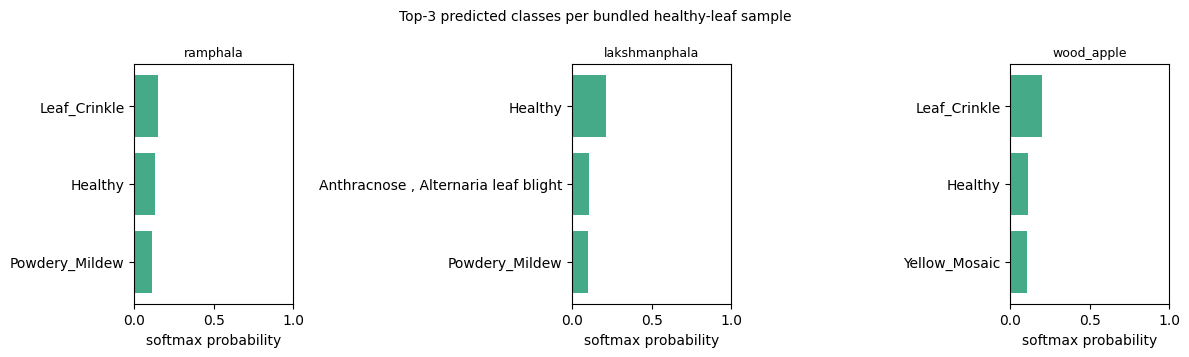

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, score) in zip(axes, predictions.items()):
    top = np.argsort(score)[::-1][:3]
    ax.barh([class_names[i] for i in top][::-1], [score[i] for i in top][::-1], color="#4a8")
    ax.set_title(name.replace("healthy_", "").replace("_leaf.jpg", ""), fontsize=9)
    ax.set_xlabel("softmax probability")
    ax.set_xlim(0, 1)
fig.suptitle("Top-3 predicted classes per bundled healthy-leaf sample", fontsize=10)
fig.tight_layout()
plt.show()

## 9. Random-Forest crop recommendation (paper branch 1)

`crop_suggestion.py` loads `crop_recommendation_model.joblib` and predicts on a 7-feature row `['N','P','K','temperature','humidity','ph','rainfall']` using the form defaults N=90, P=40, K=40, 25 °C, 70 %, pH 6.5, 100 mm. We port that prediction exactly. GUI→notebook mapping: number inputs → this fixed row; the similarity list → the next section's table.

**日本語:** 著者の`crop_suggestion.py`と同じ7特徴量（フォーム既定値 N=90, P=40, K=40, 25 ℃, 70 %, pH 6.5, 100 mm）でRandom Forestの推薦を実行します。

In [ ]:
rf_model = joblib.load(BASE / "crop_recommendation_model.joblib")
print("loaded model:", type(rf_model).__name__)

FEATURES = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']  # crop_suggestion.py input columns
soil_input = pd.DataFrame([[90, 40, 40, 25.0, 70.0, 6.5, 100.0]], columns=FEATURES)  # author's form defaults
predicted_crop = rf_model.predict(soil_input)[0]
print("predicted crop (RF, author defaults):", predicted_crop)

loaded model: RandomForestClassifier
predicted crop (RF, author defaults): coffee


## 10. Plausibility check against the paper's Soil Input Test

The paper's test 1 states: *"Enter typical soil values; expected: recommended crops match dataset label."* As a plausibility check (not an accuracy claim) we load `Crop_recommendation.csv`, show its schema, and verify whether the predicted label exists in the dataset the RF was trained on. The author's model was fit on a soil–crop dataset; its exact provenance is **not stated** in the paper, so we report what the data shows.

**日本語:** 論文のテスト1に基づき、予測ラベルがデータセットのラベル列に存在するかを確認します（精度の主張ではなく妥当性確認です）。土壌データの出典は論文に記載がない点に注意してください。

In [ ]:
crop_df = pd.read_csv(BASE / "Crop_recommendation.csv")
print("shape:", crop_df.shape, "| columns:", list(crop_df.columns))
print(crop_df.head(3))
labels = crop_df["label"].unique() if "label" in crop_df.columns else []
print(f"\n{len(labels)} distinct labels; predicted label {predicted_crop!r} present in dataset: {predicted_crop in labels}")

shape: (2224, 8) | columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice

25 distinct labels; predicted label 'coffee' present in dataset: True


## 11. "Other crops with similar conditions" (author's distance ranking)

Faithful port of `crop_suggestion.py`'s similarity block: Euclidean distance from the input row over the dataset rows, mean per label, sorted ascending, and the author's suitability formula `100 * (1 - score / max_score)` for the top 5. This ranking is computed from the actual downloaded data.

**日本語:** 著者コードの距離ベース類似作物ランキング（ユークリッド距離→ラベルごと平均→適合度%）をそのまま再現します。

In [ ]:
target = soil_input.iloc[0]
dist = np.sqrt(sum((crop_df[c] - target[c]) ** 2 for c in FEATURES))
similar = crop_df.assign(score=dist).groupby("label")["score"].mean().reset_index()
similar = similar.sort_values("score", ascending=True)
similar["suitability (%)"] = 100 * (1 - similar["score"] / similar["score"].max())
top_similar = similar.head(5).reset_index(drop=True)
top_similar

,label,score,suitability (%)
0,maize,36.258534,81.900089
1,cotton,44.204063,77.933757
2,banana,48.369532,75.854395
3,watermelon,59.997116,70.050017
4,coffee,65.085510,67.509939


## 12. Interpretation and limitations

**What was executed:** pretrained inference only, on the author's own released models and samples, inside this notebook:
- CNN leaf-disease detection on three bundled healthy-leaf images with the exact `disease_detection.py` preprocessing (224×224, no rescaling) and softmax→argmax class mapping.
- RF crop recommendation with the author's form defaults, plus the paper's qualitative plausibility check and the author's similarity ranking.

**How to read the results honestly:** the paper's qualitative test expectation is that a clear leaf image is classified correctly *with high confidence*. The saved outputs above are the actual behavior of the released model on the bundled samples — if the top class on a healthy sample is not `Healthy`, or if confidences are low (softmax spread over many classes), that is a faithful observation about this release, not a notebook error. The paper reports no accuracy figures and its results chapter consists of GUI screenshots, so there is no published reference value to compare against.

**Not covered:** training (out of scope by design), the marketing-insights branch, and the Streamlit GUI itself. The CNN's training-dataset provenance and architecture are only what the released `.keras` file reveals (section 6 output). The RF labels describe standard field crops (the released `Crop_recommendation.csv`) rather than the three indigenous fruits; the soil-dataset provenance is not stated in the paper.

**日本語:** 実行したのは推論のみです。保存された出力はリリース済みモデルの実際の挙動であり、健康葉で Healthy 以外のクラスが上位になったり信頼度が低い場合は、それがリリースの忠実な観察結果です（論文に精度の報告はありません）。マーケティング可視化とGUIは対象外です。土壌データの出典も論文に記載がありません。

## 13. References

- Suraj M S, *Smart Cultivation and Marketing of Indigenous Fruit Crops: An AI-Driven Approach*, Figshare preprint v1, 2025-12-10, DOI 10.6084/m9.figshare.30853271, CC BY 4.0 (incl. the bundled PDF and all code/data files cited above).
- Author files (MD5-verified against the record): `disease_detection.py`, `crop_suggestion.py`, `leaf_disease_model.keras`, `crop_recommendation_model.joblib`, `class_names.txt`, `class_symptoms.json`, `Crop_recommendation.csv`, three `healthy_*_leaf.jpg` samples.
- Validation record: this notebook was executed top-to-bottom in a fresh Google Colab CPU runtime; versions are in section 1 and outputs are preserved in the saved notebook.